In [2]:
# Writing a python function
import numpy as np

def leapfrog(x, v, h):
    v_new = v - h * x
    x_new = x + h * v_new

    return x_new, v_new
    
# Testing with a single particle
x = 0.5
v = 0.0
h = 0.1

x_new, v_new = leapfrog(x, v, h)

print("Single-particle test")
print(f"New position: {x_new:.6f}")
print(f"New velocity: {v_new:.6f}")


# Test with multiple particles
x = np.array([0.5, 1.0, 1.5])
v = np.array([0.0, 0.1, 0.2])

x_new, v_new = leapfrog(x, v, h)

print("\nMultiple-particle test")
print("New positions:", x_new)
print("New velocities:", v_new)

Single-particle test
New position: 0.495000
New velocity: -0.050000

Multiple-particle test
New positions: [0.495 1.    1.505]
New velocities: [-0.05  0.    0.05]


In [1]:
# Initializing half step values
x0 = 0.5
v0 = 0.0
h = 0.1
omega_p = 1.0 # Plasma frequency

a0 = -(omega_p ** 2) * x0

v_half = v0 - (h / 2) * a0

print("Initial position x0:", x0)
print("Initial velocity v0:", v0)
print("Initial acceleration a0:", a0)
print("Initial half-step velocity v(-1/2):", v_half)

Initial position x0: 0.5
Initial velocity v0: 0.0
Initial acceleration a0: -0.5
Initial half-step velocity v(-1/2): 0.025


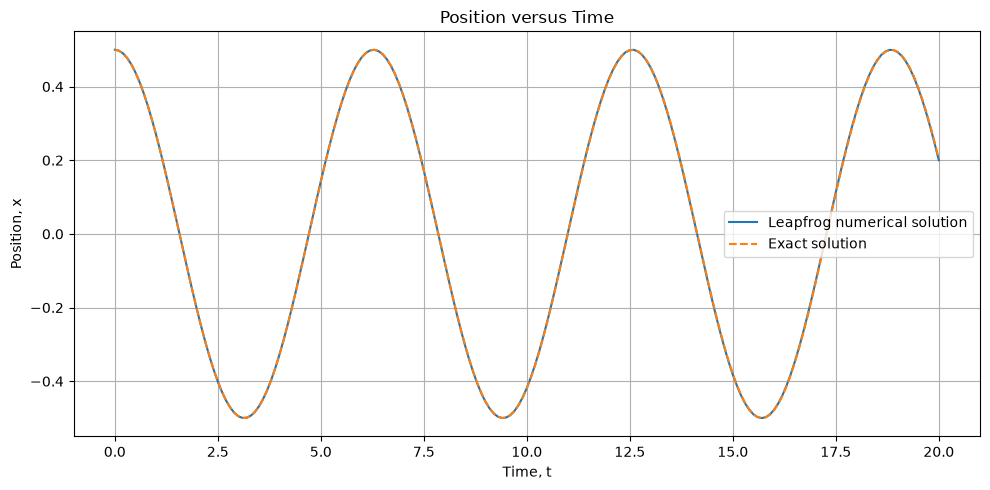

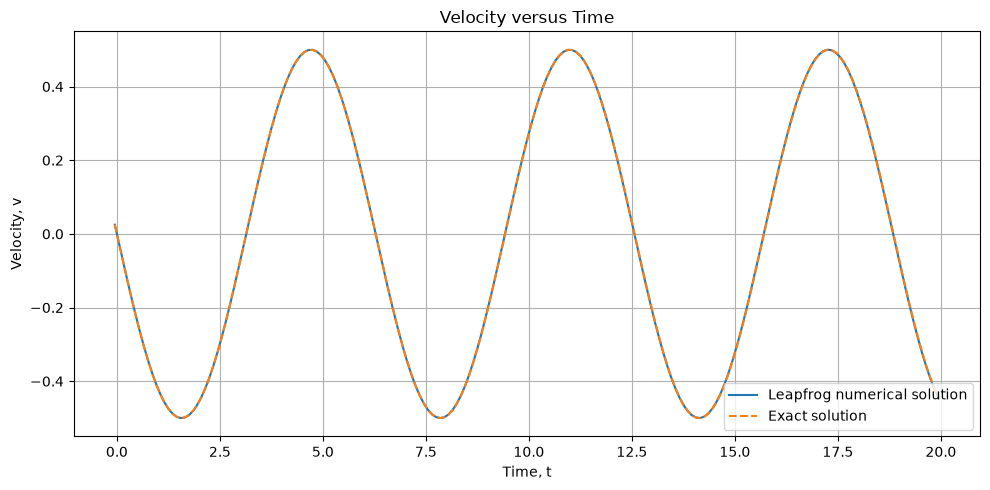

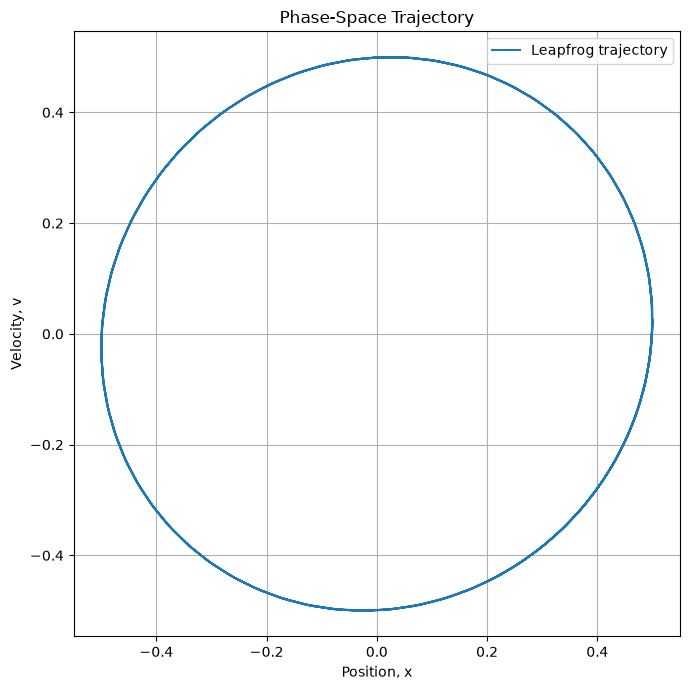

In [1]:
import numpy as np
import matplotlib.pyplot as plt


# --------------------------------------------------
# 1. Define the Leapfrog function
# --------------------------------------------------

def leapfrog(x, v, h):
   
    acceleration = -x

    v_new = v + h * acceleration
    x_new = x + h * v_new

    return x_new, v_new

#######################################

x0 = 0.5
v0 = 0.0

omega_p = 1.0

t_start = 0.0
t_end = 20.0

h = 0.1

############################################

number_of_steps = int(round((t_end - t_start) / h))

t_x = np.linspace(t_start,t_end,number_of_steps + 1)
x = np.zeros(number_of_steps + 1)
v_half = np.zeros(number_of_steps + 1)

x[0] = x0
a0 = -(omega_p ** 2) * x0
v_half[0] = v0 - (h / 2) * a0

###############################################

for n in range(number_of_steps):

    x[n + 1], v_half[n + 1] = leapfrog(x[n],v_half[n],h)

t_v = t_x - h / 2

x_exact = 0.5 * np.cos(omega_p * t_x)
v_exact = -0.5 * np.sin(omega_p * t_v)

################################################


plt.figure(figsize=(10, 5))
plt.plot(t_x,x,label="Leapfrog numerical solution")
plt.plot(t_x,x_exact,"--",label="Exact solution")
plt.xlabel("Time, t")
plt.ylabel("Position, x")
plt.title("Position versus Time")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))
plt.plot(t_v,v_half,label="Leapfrog numerical solution")
plt.plot(t_v,v_exact,"--",label="Exact solution")
plt.xlabel("Time, t")
plt.ylabel("Velocity, v")
plt.title("Velocity versus Time")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 7))
plt.plot(x,v_half,label="Leapfrog trajectory")
plt.xlabel("Position, x")
plt.ylabel("Velocity, v")
plt.title("Phase-Space Trajectory")
plt.grid(True)
plt.legend()
plt.axis("equal")
plt.tight_layout()
plt.show()

In [5]:
# Convergence with correct initialization
import numpy as np

x0 = 0.5
v0 = 0.0
omega_p = 1.0
t_end = 20.0
time_steps = [0.2, 0.1, 0.05, 0.025]

###########################################

def solve_leapfrog(h, staggered=True):
   
    number_of_steps = int(round(t_end / h))

    t = np.linspace(0.0,t_end,number_of_steps + 1)
    x = np.zeros(number_of_steps + 1)
    v_half = np.zeros(number_of_steps + 1)
    x[0] = x0
    a0 = -(omega_p ** 2) * x0

    if staggered:
        v_half[0] = v0 - (h / 2) * a0
    else:
        v_half[0] = v0

    for n in range(number_of_steps):
        v_half[n + 1] = (v_half[n]- h * (omega_p ** 2) * x[n])
        x[n + 1] = (x[n]+ h * v_half[n + 1])

    return t, x, v_half

##########################################

errors_staggered = []

for h in time_steps:
    t, x, v_half = solve_leapfrog(h,staggered=True)
    x_exact = 0.5 * np.cos(omega_p * t)

    max_error = np.max(np.abs(x - x_exact))
    errors_staggered.append(max_error)


orders_staggered = [np.nan]

for i in range(len(time_steps) - 1):
    order = np.log2(errors_staggered[i]/ errors_staggered[i + 1])
    orders_staggered.append(order)


###############################################

print("Convergence with correct half-step initialization")
print(f"{'h':>10}"f"{'Maximum error':>25}"f"{'Observed order':>25}")

for h, error, order in zip(time_steps,errors_staggered,orders_staggered):

    if np.isnan(order):
        order_text = "---"
    else:
        order_text = f"{order:.6f}"

    print(f"{h:10.4f}"f"{error:25.10e}"f"{order_text:>25}")

Convergence with correct half-step initialization
         h            Maximum error           Observed order
    0.2000         1.5396153503e-02                      ---
    0.1000         3.8152808690e-03                 2.012709
    0.0500         9.5169455806e-04                 2.003219
    0.0250         2.3779054510e-04                 2.000807


In [8]:
# Convergence with unstaggered initial velocity
errors_unstaggered = []

for h in time_steps:
    t, x, v_half = solve_leapfrog(h,staggered=False)
    x_exact = 0.5 * np.cos(omega_p * t)

    max_error = np.max(np.abs(x - x_exact))
    errors_unstaggered.append(max_error)


orders_unstaggered = [np.nan]

for i in range(len(time_steps) - 1):
    order = np.log2(errors_unstaggered[i]/ errors_unstaggered[i + 1])
    orders_unstaggered.append(order)


############################################


print("Convergence with unstaggered initialization")
print(f"{'h':>10}"f"{'Maximum error':>25}"f"{'Observed order':>25}")

for h, error, order in zip(time_steps,errors_unstaggered,orders_unstaggered):

    if np.isnan(order):
        order_text = "---"
    else:
        order_text = f"{order:.6f}"

    print(f"{h:10.4f}"f"{error:25.10e}"f"{order_text:>25}")

Convergence with unstaggered initialization
         h            Maximum error           Observed order
    0.2000         6.4557093735e-02                      ---
    0.1000         2.8628279982e-02                 1.173135
    0.0500         1.3401662702e-02                 1.095029
    0.0250         6.4754034103e-03                 1.049370


In [3]:
import numpy as np

x0 = 0.5
v0 = 0.0
h = 0.1
omega_p = 1.0
t_end = 20.0

def solve_leapfrog(h, staggered=True):
   
    number_of_steps = int(round(t_end / h))

    t = np.linspace(0.0,t_end,number_of_steps + 1)
    x = np.zeros(number_of_steps + 1)
    v_half = np.zeros(number_of_steps + 1)
    x[0] = x0
    a0 = -(omega_p ** 2) * x0

    if staggered:
        v_half[0] = v0 - (h / 2) * a0
    else:
        v_half[0] = v0

    for n in range(number_of_steps):
        v_half[n + 1] = (v_half[n]- h * (omega_p ** 2) * x[n])
        x[n + 1] = (x[n]+ h * v_half[n + 1])

    return t, x, v_half

t, x, v_half = solve_leapfrog(h,staggered=True)

lhs = x[2:] - 2 * x[1:-1] + x[:-2]
rhs = -(omega_p ** 2) * (h ** 2) * x[1:-1]
residual = lhs - rhs
print("Maximum absolute residual:",np.max(np.abs(residual)))

Maximum absolute residual: 7.37257477290143e-17


All four stability cases have been calculated.


<Figure size 1100x600 with 0 Axes>

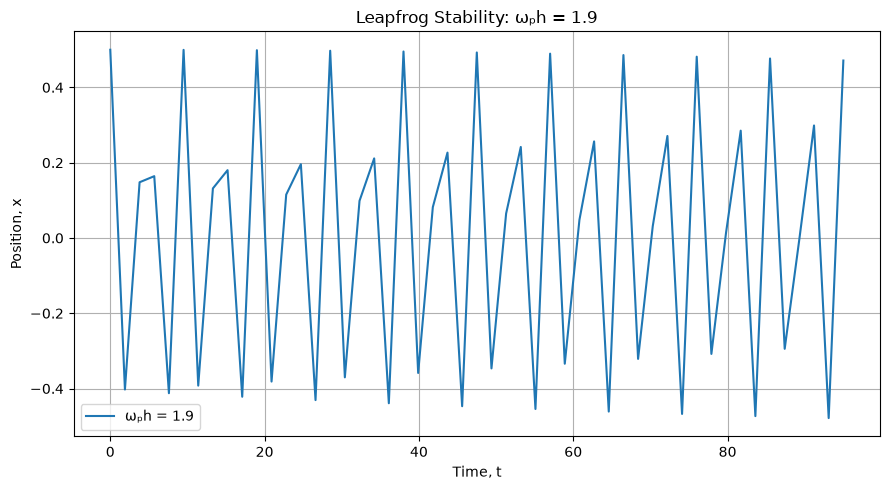

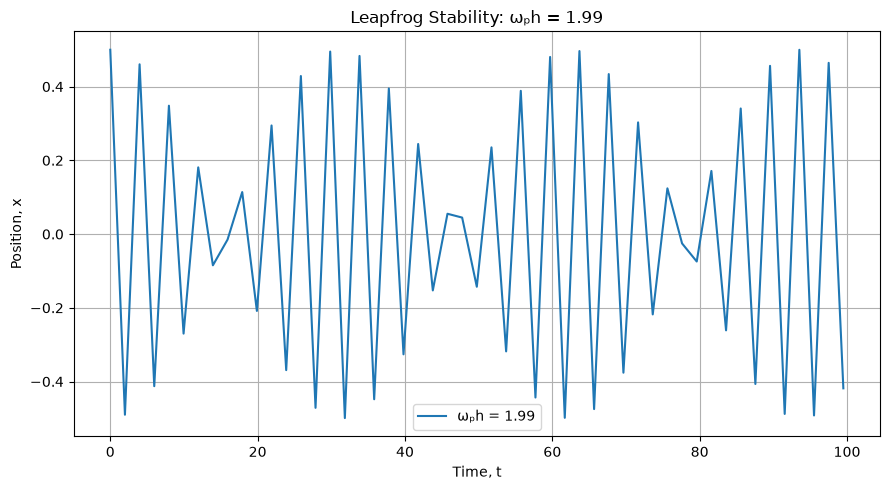

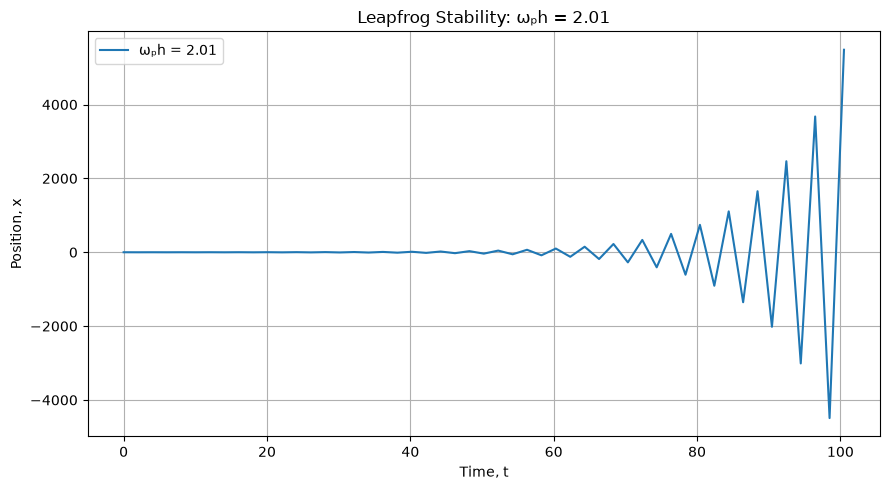

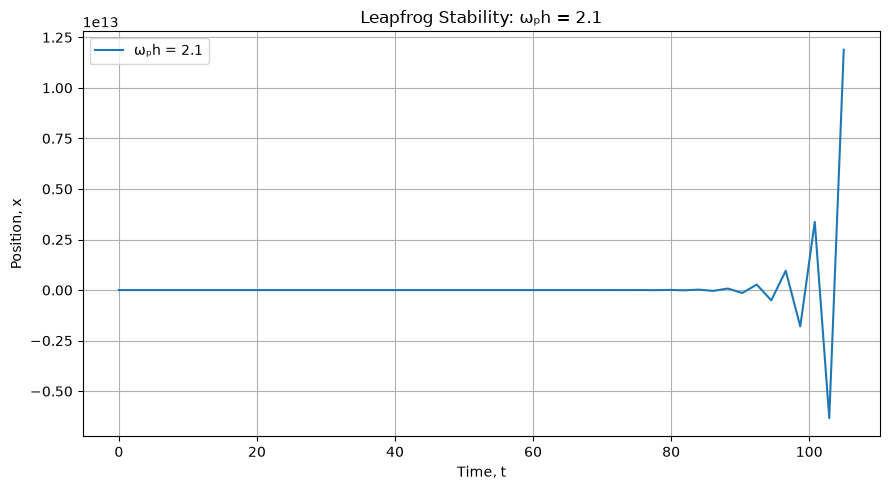

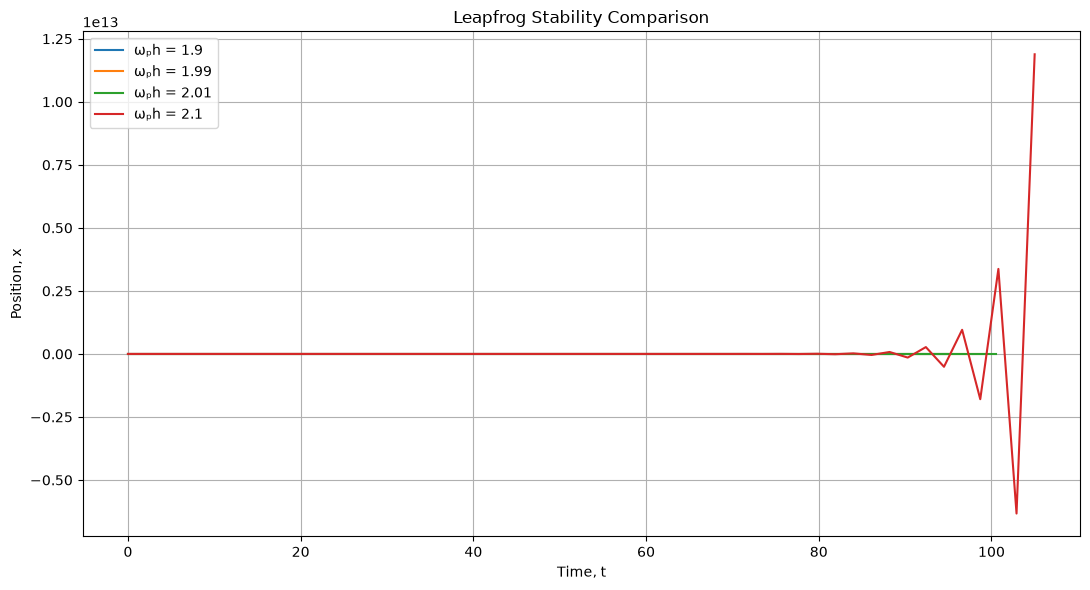

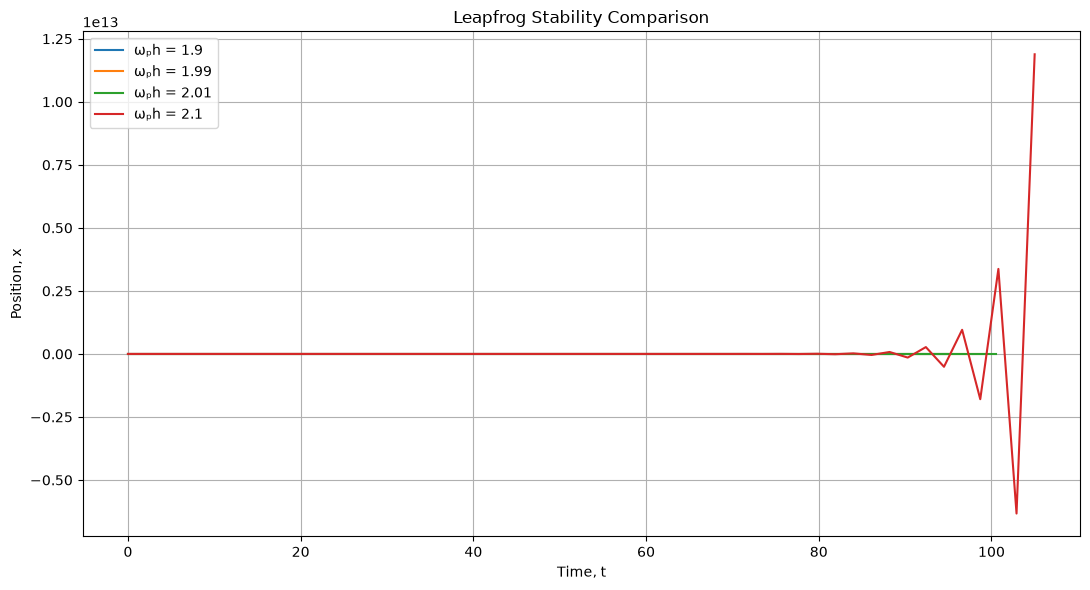

In [11]:
# Deriving stability and comparison
import numpy as np
import matplotlib.pyplot as plt

x0 = 0.5
v0 = 0.0
omega_p = 1.0
mu_values = [1.9, 1.99, 2.01, 2.1]
number_of_steps = 50

plt.figure(figsize=(11, 6))


for mu in mu_values:
    h = mu / omega_p
    t = np.arange(number_of_steps + 1) * h
    x = np.zeros(number_of_steps + 1)
    v_half = np.zeros(number_of_steps + 1)

    x[0] = x0
    a0 = -(omega_p ** 2) * x0
    v_half[0] = v0 - (h / 2) * a0

    for n in range(number_of_steps):
        v_half[n + 1] = (v_half[n]- h * (omega_p ** 2) * x[n])
        x[n + 1] = (x[n]+ h * v_half[n + 1])
    solutions[mu] = (t, x)
print("All four stability cases have been calculated.")

#######################################################

for mu in mu_values:
    t, x = solutions[mu]

    plt.figure(figsize=(9, 5))
    plt.plot(t, x, label=f"ωₚh = {mu}")

    plt.xlabel("Time, t")
    plt.ylabel("Position, x")
    plt.title(f"Leapfrog Stability: ωₚh = {mu}")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

#########################################################

plt.figure(figsize=(11, 6))

for mu in mu_values:
    t, x = solutions[mu]
    plt.plot(t,x,label=f"ωₚh = {mu}")

plt.xlabel("Time, t")
plt.ylabel("Position, x")
plt.title("Leapfrog Stability Comparison")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
plt.figure(figsize=(11, 6))

